In [1]:
import kagglehub
import os
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. تحميل الداتا سيت من Kaggle
path = kagglehub.dataset_download("rahibvk/real-diabetes-lab-results-and-biomarkers-anti-pima")

# 2. قراءة ملف الـ CSV
file_path = os.path.join(path, 'custom_multi_year_diabetes_dataset.csv')
df = pd.read_csv(file_path)

# 3. معالجة وتحديد الـ Target والخصائص (Features)
df['Binary_Target'] = (df['Diabetes_Status'] > 0).astype(int)
df['Gender_Num'] = df['Gender'].map({'Male': 1, 'Female': 0})
feature_columns = ['Age', 'Gender_Num', 'BMI', 'Systolic_BP', 'Diastolic_BP', 'HbA1c_Level']

X = df[feature_columns].values
y = df['Binary_Target'].values

# 4. تقسيم البيانات وتطبيق الـ StandardScaler
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("تم قراءة وتجهيز البيانات بنجاح وجاهزة للتدريب!")

Using Colab cache for faster access to the 'real-diabetes-lab-results-and-biomarkers-anti-pima' dataset.
تم قراءة وتجهيز البيانات بنجاح وجاهزة للتدريب!


Using Colab cache for faster access to the 'real-diabetes-lab-results-and-biomarkers-anti-pima' dataset.


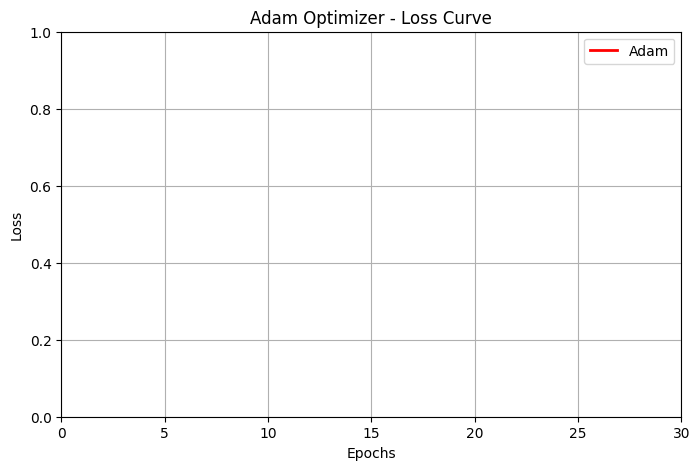

تم تدريب نموذج Adam بنجاح وعرض المنحنى الأحمر! مبروك إنجاز الواجب كاملًا!


In [2]:
import kagglehub
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. تحميل الداتا وتجهيزها
path = kagglehub.dataset_download("rahibvk/real-diabetes-lab-results-and-biomarkers-anti-pima")
file_path = os.path.join(path, 'custom_multi_year_diabetes_dataset.csv')
df = pd.read_csv(file_path)

df['Binary_Target'] = (df['Diabetes_Status'] > 0).astype(int)
df['Gender_Num'] = df['Gender'].map({'Male': 1, 'Female': 0})
feature_columns = ['Age', 'Gender_Num', 'BMI', 'Systolic_BP', 'Diastolic_BP', 'HbA1c_Level']

X = df[feature_columns].values
y = df['Binary_Target'].values

# 2. التقسيم والتطبيع
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 3. الدوال الأساسية
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

def compute_loss(y_true, y_pred_proba):
    epsilon = 1e-15
    y_pred_proba = np.clip(y_pred_proba, epsilon, 1 - epsilon)
    m = len(y_true)
    return -(1 / m) * np.sum(y_true * np.log(y_pred_proba) + (1 - y_true) * np.log(1 - y_pred_proba))

# 4. كلاس Adam Logistic Regression
class AdamLogisticRegression:
    def __init__(self, lr=0.01, epochs=30, beta1=0.9, beta2=0.999, epsilon=1e-8):
        self.lr = lr
        self.epochs = epochs
        self.beta1 = beta1
        self.beta2 = beta2
        self.epsilon = epsilon
        self.loss_history = []

    def fit(self, X, y):
        m, n = X.shape
        self.w = np.zeros(n)
        self.b = 0.0
        self.loss_history = []

        # معاملات العزم الأول والثاني لـ Adam
        m_dw = np.zeros(n)
        v_dw = np.zeros(n)
        m_db = 0.0
        v_db = 0.0

        for epoch in range(1, self.epochs + 1):
            z = np.dot(X, self.w) + self.b
            y_hat = sigmoid(z)

            dw = (1 / m) * np.dot(X.T, (y_hat - y))
            db = (1 / m) * np.sum(y_hat - y)

            # تحديث العزم الأول والثاني
            m_dw = self.beta1 * m_dw + (1 - self.beta1) * dw
            m_db = self.beta1 * m_db + (1 - self.beta1) * db

            v_dw = self.beta2 * v_dw + (1 - self.beta2) * (dw ** 2)
            v_db = self.beta2 * v_db + (1 - self.beta2) * (db ** 2)

            # تصحيح الانحياز (Bias Correction)
            m_dw_corrected = m_dw / (1 - (self.beta1 ** epoch))
            m_db_corrected = m_db / (1 - (self.beta1 ** epoch))

            v_dw_corrected = v_dw / (1 - (self.beta2 ** epoch))
            v_db_corrected = v_db / (1 - (self.beta2 ** epoch))

            # تحديث الأوزان والانحياز
            self.w -= self.lr * m_dw_corrected / (np.sqrt(v_dw_corrected) + self.epsilon)
            self.b -= self.lr * m_db_corrected / (np.sqrt(v_db_corrected) + self.epsilon)

            loss = compute_loss(y, y_hat)
            self.loss_history.append(loss)

# 5. التدريب ورسم المنحنى
model_adam = AdamLogisticRegression(lr=0.01, epochs=30)
model_adam.fit(X_train, y_train)

plt.figure(figsize=(8, 5))
plt.plot(model_adam.loss_history, label='Adam', color='red', linewidth=2)

plt.xlim(0, len(model_adam.loss_history))
plt.ylim(0, 1.0)

plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Adam Optimizer - Loss Curve')
plt.legend()
plt.grid(True)
plt.show()

print("تم تدريب نموذج Adam بنجاح وعرض المنحنى الأحمر! مبروك إنجاز الواجب كاملًا!")